# EDA — nature des rendements de marché Fama–French

**Question :** quelles propriétés des rendements bruts déterminent la forme, la persistance et les limites de notre mesure de volatilité future à cinq séances ?

Ce notebook reste descriptif. Il utilise exclusivement le millésime déjà validé et ne modifie aucune observation. Il exclut explicitement : nouveaux modèles ou nouvelles cibles, variables économiques, détection de crises ou de régimes, tests statistiques avancés, suppression automatique des extrêmes, analyse de facteurs inutilisés et répétition exhaustive des notebooks 01–03.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_URL = (
    'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
    'F-F_Research_Data_Factors_daily_CSV.zip'
)
EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
ANNUALIZATION_DAYS = 252
plt.style.use('seaborn-v0_8-whitegrid')
print(f'pandas={pd.__version__}; numpy={np.__version__}')

pandas=2.2.3; numpy=2.2.1


## 1. Provenance et structure

La copie locale immuable est prioritaire. Un téléchargement de repli n'est accepté que si son SHA-256 correspond exactement au millésime validé. `SMB` et `HML` sont identifiés dans le schéma, mais ne sont pas analysés : ils ne font pas partie de notre question actuelle.

In [2]:
loaded_at_utc = datetime.now(timezone.utc).isoformat()
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
local_snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
if local_snapshot is not None:
    archive_bytes = local_snapshot.read_bytes()
    data_origin = f'copie locale immuable : {local_snapshot.as_posix()}'
else:
    with urlopen(SOURCE_URL, timeout=60) as response:
        archive_bytes = response.read()
    data_origin = 'téléchargement en mémoire depuis la source officielle'
archive_sha256 = sha256(archive_bytes).hexdigest()
assert archive_sha256 == EXPECTED_SHA256, (
    f'Empreinte inattendue : {archive_sha256}. Empreinte attendue : {EXPECTED_SHA256}.'
)

with ZipFile(BytesIO(archive_bytes)) as archive:
    members = archive.namelist()
    assert len(members) == 1, members
    member_name = members[0]
    text = archive.read(member_name).decode('utf-8-sig')
lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break
factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0
market_return_pct = 100 * market_return

schema = pd.DataFrame({
    'type': factors.dtypes.astype(str),
    'unité_source': ['pourcentage quotidien'] * len(factors.columns),
    'utilisation_actuelle': ['oui, avec RF', 'non', 'non', 'oui, avec Mkt-RF'],
})
print(f'Millésime : {lines[0]}')
print(f'Origine : {data_origin}')
print(f'Chargé à : {loaded_at_utc}')
print(f'SHA-256 : {archive_sha256}')
print(f'Fichier interne : {member_name}; {len(archive_bytes):,} octets ZIP')
print(f'Période : {factors.index.min().date()} → {factors.index.max().date()}')
print(f'Observations : {len(factors):,}')
print('\nSchéma :')
print(schema.to_string())
print('\nRendement utilisé : market_return = (Mkt-RF + RF) / 100, en décimal.')

Millésime : This file was created by using the 202608 CRSP database.
Origine : copie locale immuable : data/raw/fama_french/F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
Chargé à : 2026-10-15T00:59:39.778208+00:00
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Fichier interne : F-F_Research_Data_Factors_daily.csv; 178,184 octets ZIP
Période : 1926-07-01 → 2026-08-31
Observations : 26,317

Schéma :
           type           unité_source utilisation_actuelle
Mkt-RF  float64  pourcentage quotidien         oui, avec RF
SMB     float64  pourcentage quotidien                  non
HML     float64  pourcentage quotidien                  non
RF      float64  pourcentage quotidien     oui, avec Mkt-RF

Rendement utilisé : market_return = (Mkt-RF + RF) / 100, en décimal.


## 2. Qualité et calendrier

Le calendrier est celui du fichier source. Aucune fréquence quotidienne artificielle n'est créée, aucun jour absent n'est ajouté et aucune valeur n'est imputée. Les interruptions sont mesurées en jours civils entre deux séances consécutives de la source.

In [3]:
assert factors.index.is_monotonic_increasing
assert not factors.index.has_duplicates
assert len(factors) == len(data_lines) - 1
assert market_return.index.equals(factors.index)

quality = pd.Series({
    'lignes_source': len(factors),
    'dates_dupliquées': int(factors.index.duplicated().sum()),
    'valeurs_manquantes_facteurs': int(factors.isna().sum().sum()),
    'rendements_marche_manquants': int(market_return.isna().sum()),
    'séances_samedi': int((factors.index.dayofweek == 5).sum()),
    'séances_dimanche': int((factors.index.dayofweek == 6).sum()),
    'dates_ajoutées_artificiellement': 0,
})
date_series = factors.index.to_series()
gaps = pd.DataFrame({
    'date_précédente': date_series.shift(1),
    'date_suivante': date_series,
    'écart_jours_civils': date_series.diff().dt.days,
}).dropna().nlargest(12, 'écart_jours_civils')
observations_per_year = factors.groupby(factors.index.year).size().rename('observations')
print(quality.to_string())
print('\nDouze plus grandes interruptions calendaires :')
print(gaps.to_string(index=False))
print('\nObservations annuelles — résumé :')
print(observations_per_year.describe().round(1).to_string())
print(f'Années partielles : {observations_per_year.index[0]} et {observations_per_year.index[-1]}.')

lignes_source                      26317
dates_dupliquées                       0
valeurs_manquantes_facteurs            0
rendements_marche_manquants            0
séances_samedi                      1158
séances_dimanche                       0
dates_ajoutées_artificiellement        0

Douze plus grandes interruptions calendaires :
date_précédente date_suivante  écart_jours_civils
     1933-03-03    1933-03-15                12.0
     2001-09-10    2001-09-17                 7.0
     1929-11-27    1929-12-02                 5.0
     1956-12-21    1956-12-26                 5.0
     1958-12-24    1958-12-29                 5.0
     1961-05-26    1961-05-31                 5.0
     1968-07-03    1968-07-08                 5.0
     2006-12-29    2007-01-03                 5.0
     2012-10-26    2012-10-31                 5.0
     1926-07-02    1926-07-06                 4.0
     1926-09-03    1926-09-07                 4.0
     1928-04-05    1928-04-09                 4.0

Observations a

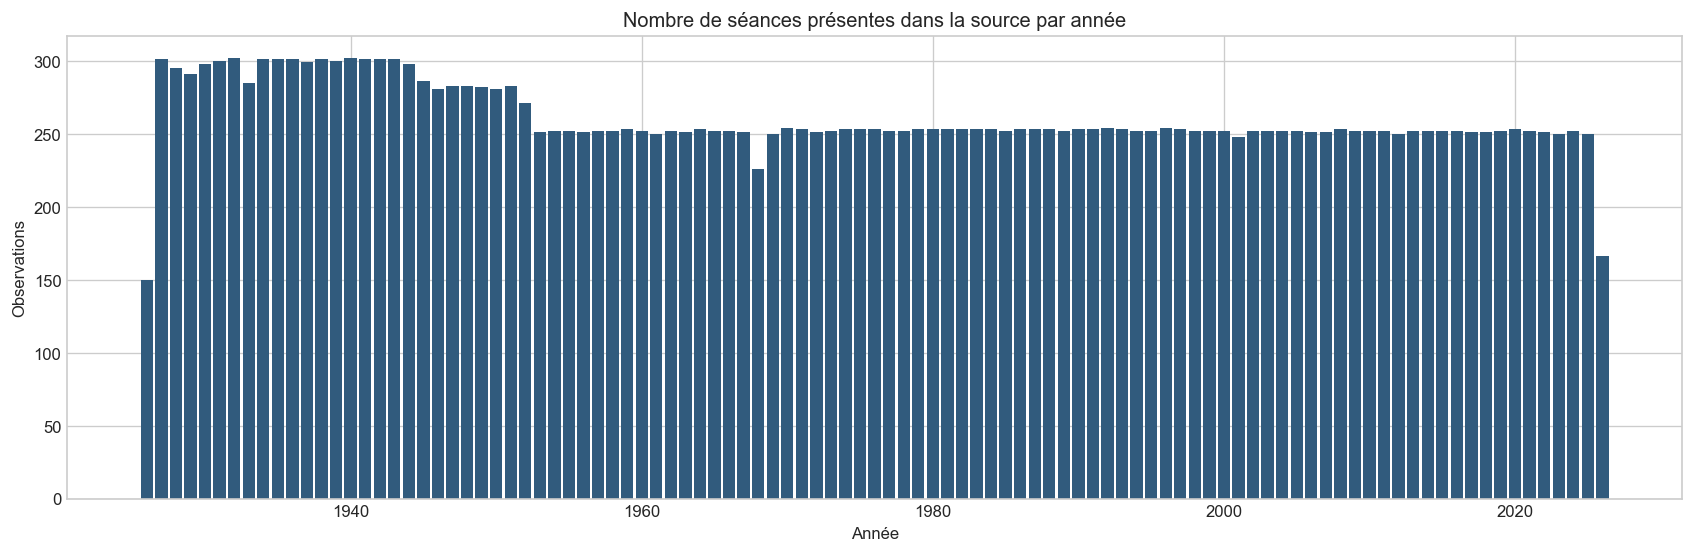

In [4]:
fig, ax = plt.subplots(figsize=(14, 4.5), constrained_layout=True)
ax.bar(observations_per_year.index, observations_per_year.values, color='#315b7d', width=0.85)
ax.set(title='Nombre de séances présentes dans la source par année', xlabel='Année', ylabel='Observations')
plt.show()

## 3. Distribution des rendements

Les statistiques sont descriptives. L'asymétrie et la kurtosis excédentaire résument la forme empirique sans test d'hypothèse. Les valeurs extrêmes sont conservées intégralement.

In [5]:
return_summary = pd.Series({
    'minimum_pct': market_return_pct.min(),
    'q001_pct': market_return_pct.quantile(0.001),
    'q01_pct': market_return_pct.quantile(0.01),
    'q05_pct': market_return_pct.quantile(0.05),
    'médiane_pct': market_return_pct.median(),
    'moyenne_pct': market_return_pct.mean(),
    'écart_type_pct': market_return_pct.std(),
    'q95_pct': market_return_pct.quantile(0.95),
    'q99_pct': market_return_pct.quantile(0.99),
    'q999_pct': market_return_pct.quantile(0.999),
    'maximum_pct': market_return_pct.max(),
    'asymétrie': market_return_pct.skew(),
    'kurtosis_excédentaire': market_return_pct.kurt(),
})
positive = market_return_pct[market_return_pct > 0]
negative_magnitude = -market_return_pct[market_return_pct < 0]
sign_summary = pd.DataFrame({
    'hausse': [len(positive), positive.mean(), positive.median(), positive.quantile(0.95), positive.max()],
    'baisse_en_valeur_absolue': [len(negative_magnitude), negative_magnitude.mean(), negative_magnitude.median(), negative_magnitude.quantile(0.95), negative_magnitude.max()],
}, index=['nombre', 'moyenne_pct', 'médiane_pct', 'q95_pct', 'maximum_pct'])
largest_gains = market_return_pct.nlargest(10).rename('rendement_pct').to_frame()
largest_losses = market_return_pct.nsmallest(10).rename('rendement_pct').to_frame()
print(return_summary.round(4).to_string())
print(f'Nombre de rendements exactement nuls : {(market_return_pct == 0).sum()}')
print('\nComparaison descriptive par signe :')
print(sign_summary.round(4).to_string())
print('\nDix plus fortes hausses :')
print(largest_gains.round(2).to_string())
print('\nDix plus fortes baisses :')
print(largest_losses.round(2).to_string())

minimum_pct             -17.4100
q001_pct                 -6.5942
q01_pct                  -3.0684
q05_pct                  -1.5700
médiane_pct               0.0800
moyenne_pct               0.0431
écart_type_pct            1.0770
q95_pct                   1.5100
q99_pct                   2.9884
q999_pct                  6.4500
maximum_pct              15.6700
asymétrie                -0.1662
kurtosis_excédentaire    16.1250
Nombre de rendements exactement nuls : 173

Comparaison descriptive par signe :
                hausse  baisse_en_valeur_absolue
nombre       14397.000                11747.0000
moyenne_pct      0.675                    0.7307
médiane_pct      0.460                    0.4700
q95_pct          1.950                    2.2900
maximum_pct     15.670                   17.4100

Dix plus fortes hausses :
            rendement_pct
date                     
1933-03-15          15.67
2008-10-13          11.36
1929-10-30          11.22
1931-10-06          11.15
1932-09-21    

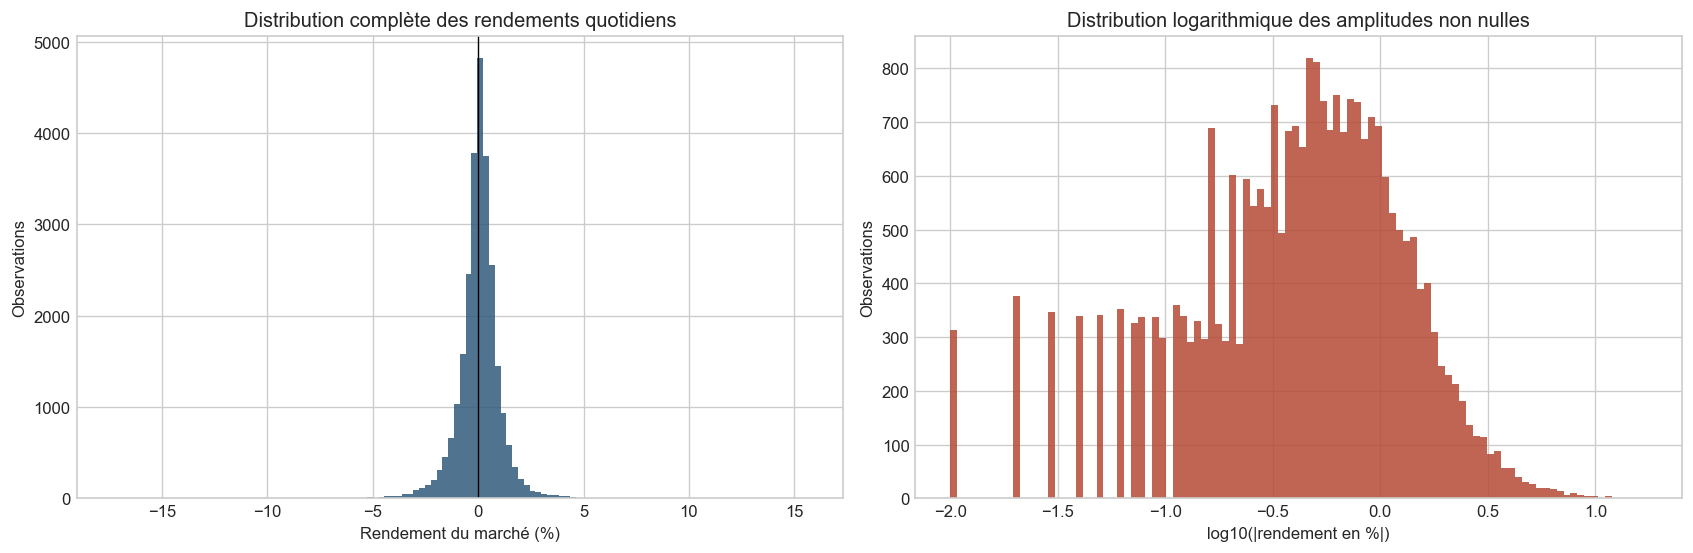

In [6]:
nonzero_abs_returns = market_return_pct.abs()[market_return_pct != 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].hist(market_return_pct, bins=120, color='#315b7d', alpha=0.85)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set(title='Distribution complète des rendements quotidiens', xlabel='Rendement du marché (%)', ylabel='Observations')
axes[1].hist(np.log10(nonzero_abs_returns), bins=100, color='#b54a35', alpha=0.85)
axes[1].set(title='Distribution logarithmique des amplitudes non nulles', xlabel='log10(|rendement en %|)', ylabel='Observations')
plt.show()

## 4. Dépendance temporelle

L'autocorrélation des rendements mesure une dépendance linéaire directionnelle. Celle des rendements absolus et au carré décrit la persistance de l'amplitude. Une différence entre les deux est compatible avec une faible prévisibilité du signe mais une amplitude persistante ; elle ne prouve ni causalité ni exploitabilité hors échantillon.

Autocorrélations sélectionnées :
                  rendement  rendement_absolu  rendement_au_carré
décalage_séances                                                 
1                     0.046             0.298               0.259
2                    -0.025             0.331               0.301
5                     0.006             0.309               0.231
10                    0.013             0.256               0.157
22                   -0.005             0.211               0.100
60                   -0.004             0.139               0.058

Seuil descriptif rétrospectif du 99e centile de |r| : 3.91 %
Observations au-dessus du seuil : 264
Séquences contiguës : 208
Longueur maximale d’une séquence : 8 séances


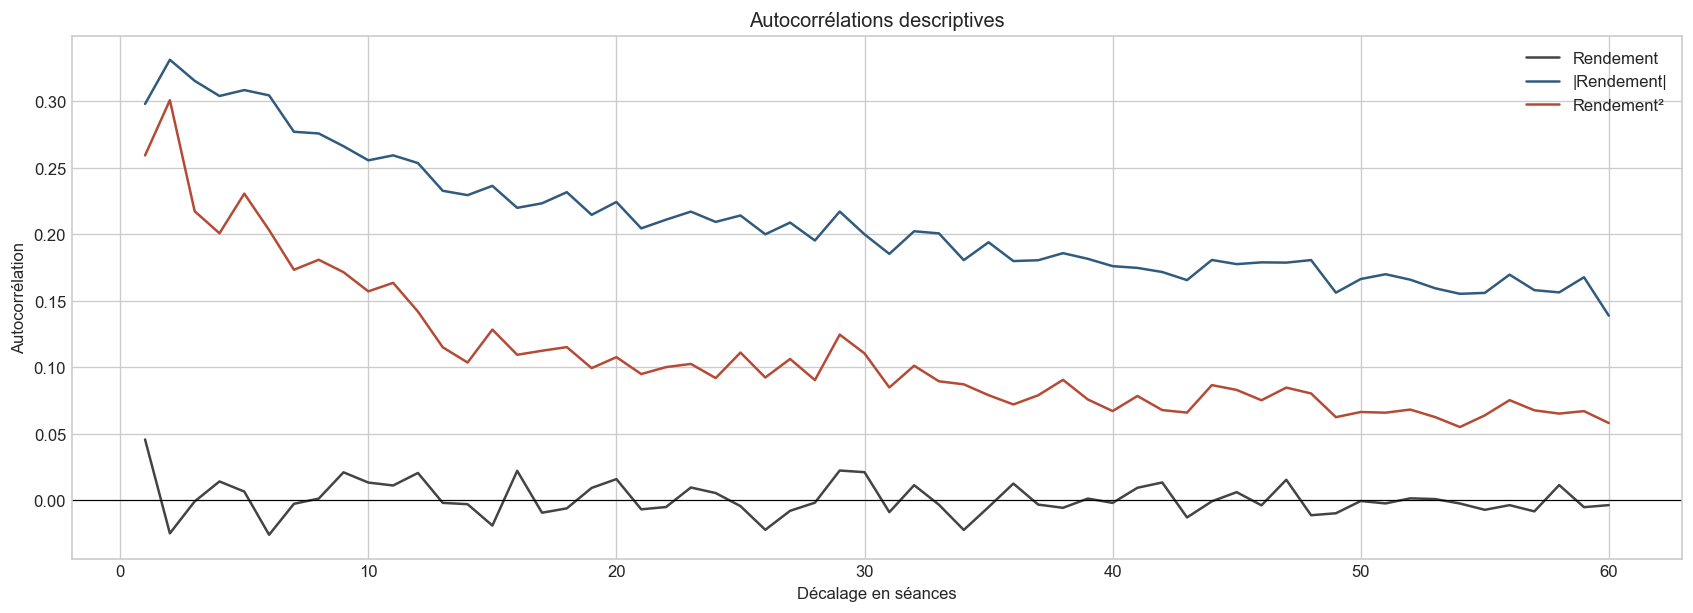

In [7]:
max_lag = 60
acf = pd.DataFrame({
    'rendement': [market_return.autocorr(lag) for lag in range(1, max_lag + 1)],
    'rendement_absolu': [market_return.abs().autocorr(lag) for lag in range(1, max_lag + 1)],
    'rendement_au_carré': [market_return.pow(2).autocorr(lag) for lag in range(1, max_lag + 1)],
}, index=range(1, max_lag + 1))
acf.index.name = 'décalage_séances'
selected_lags = [1, 2, 5, 10, 22, 60]
print('Autocorrélations sélectionnées :')
print(acf.loc[selected_lags].round(3).to_string())

absolute_threshold = market_return_pct.abs().quantile(0.99)
is_large = market_return_pct.abs() >= absolute_threshold
run_id = is_large.ne(is_large.shift(fill_value=False)).cumsum()
large_runs = is_large[is_large].groupby(run_id[is_large]).size()
print(f'\nSeuil descriptif rétrospectif du 99e centile de |r| : {absolute_threshold:.2f} %')
print(f'Observations au-dessus du seuil : {int(is_large.sum())}')
print(f'Séquences contiguës : {len(large_runs)}')
print(f'Longueur maximale d’une séquence : {int(large_runs.max())} séances')

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(acf.index, acf['rendement'], label='Rendement', color='#444444')
ax.plot(acf.index, acf['rendement_absolu'], label='|Rendement|', color='#315b7d')
ax.plot(acf.index, acf['rendement_au_carré'], label='Rendement²', color='#b54a35')
ax.axhline(0, color='black', linewidth=0.7)
ax.set(title='Autocorrélations descriptives', xlabel='Décalage en séances', ylabel='Autocorrélation')
ax.legend()
plt.show()

## 5. Évolution historique descriptive

Les résumés annuels et décennaux décrivent l'instabilité de la distribution. Ils ne définissent aucun régime. Le seuil d'amplitude extrême est le 99e centile global calculé rétrospectivement ; il n'est pas disponible en temps réel. Les années 1926 et 2026 sont partielles.

Distribution descriptive par décennie :
          count   mean    std  médiane_abs_pct  q95_abs_pct  q99_abs_pct
décennie                                                                
1920       1037  0.059  1.197             0.44        1.920        5.291
1930       2988  0.014  1.748             0.80        3.600        6.291
1940       2918  0.033  0.796             0.35        1.562        2.950
1950       2598  0.066  0.632             0.35        1.250        1.980
1960       2489  0.034  0.624             0.32        1.216        2.080
1970       2526  0.027  0.837             0.47        1.700        2.585
1980       2528  0.066  0.965             0.46        1.767        2.857
1990       2528  0.069  0.840             0.43        1.723        2.627
2000       2515  0.008  1.405             0.65        2.823        4.820
2010       2516  0.055  0.958             0.46        1.982        3.287
2020       1674  0.066  1.312             0.62        2.453        4.369


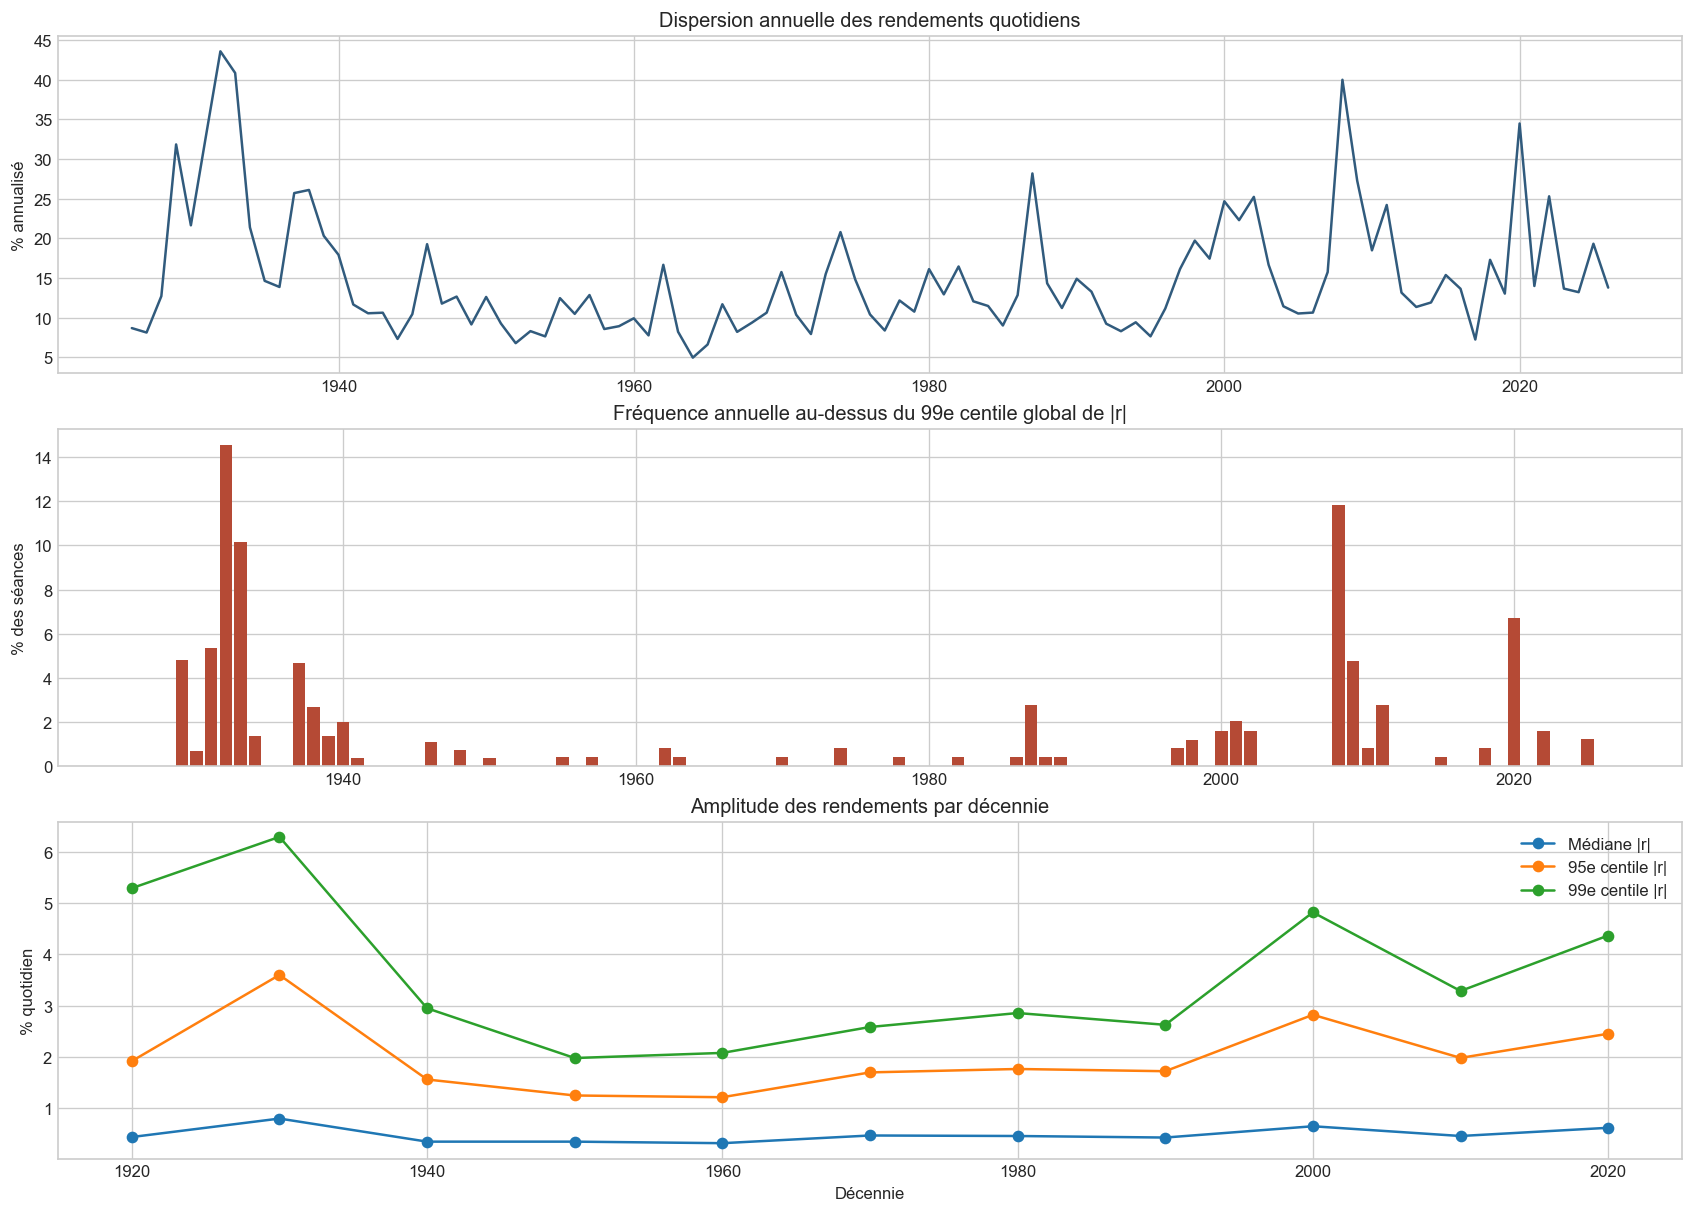

In [8]:
annual = pd.DataFrame({
    'observations': market_return_pct.groupby(market_return_pct.index.year).size(),
    'dispersion_annualisée_pct': market_return_pct.groupby(market_return_pct.index.year).std() * np.sqrt(ANNUALIZATION_DAYS),
    'fréquence_extrême_pct': 100 * is_large.groupby(is_large.index.year).mean(),
})
decade = (market_return_pct.index.year // 10) * 10
decade_summary = market_return_pct.groupby(decade).agg(['count', 'mean', 'std'])
decade_summary['médiane_abs_pct'] = market_return_pct.abs().groupby(decade).median()
decade_summary['q95_abs_pct'] = market_return_pct.abs().groupby(decade).quantile(0.95)
decade_summary['q99_abs_pct'] = market_return_pct.abs().groupby(decade).quantile(0.99)
decade_summary.index.name = 'décennie'
print('Distribution descriptive par décennie :')
print(decade_summary.round(3).to_string())

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False, constrained_layout=True)
axes[0].plot(annual.index, annual['dispersion_annualisée_pct'], color='#315b7d')
axes[0].set(title='Dispersion annuelle des rendements quotidiens', ylabel='% annualisé')
axes[1].bar(annual.index, annual['fréquence_extrême_pct'], color='#b54a35', width=0.85)
axes[1].set(title='Fréquence annuelle au-dessus du 99e centile global de |r|', ylabel='% des séances')
axes[2].plot(decade_summary.index, decade_summary['médiane_abs_pct'], marker='o', label='Médiane |r|')
axes[2].plot(decade_summary.index, decade_summary['q95_abs_pct'], marker='o', label='95e centile |r|')
axes[2].plot(decade_summary.index, decade_summary['q99_abs_pct'], marker='o', label='99e centile |r|')
axes[2].set(title='Amplitude des rendements par décennie', xlabel='Décennie', ylabel='% quotidien')
axes[2].legend()
plt.show()

## 6. Conséquences pour la cible RV5

Un rendement observé à la séance $s$ entre dans cinq cibles successives, associées aux dates d'origine allant de cinq à une séance avant $s$. L'exemple ci-dessous utilise rétrospectivement le rendement d'amplitude maximale pour rendre ce chevauchement concret. Il ne constitue pas une nouvelle cible ni une expérience prédictive.

In [9]:
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)},
    axis=1,
)
future_energy = future_returns.pow(2).sum(axis=1, min_count=HORIZON)
rv_5 = np.sqrt((ANNUALIZATION_DAYS / HORIZON) * future_energy)
largest_date = market_return.abs().idxmax()
largest_position = factors.index.get_loc(largest_date)
largest_return_sq = float(market_return.loc[largest_date] ** 2)
overlap_rows = []
for distance in range(HORIZON, 0, -1):
    origin_position = largest_position - distance
    origin_date = factors.index[origin_position]
    target_dates = factors.index[origin_position + 1:origin_position + 1 + HORIZON]
    overlap_rows.append({
        'date_t': origin_date.date().isoformat(),
        'cible_début': target_dates.min().date().isoformat(),
        'cible_fin': target_dates.max().date().isoformat(),
        'position_du_grand_rendement_dans_la_cible': distance,
        'rv5_pct': 100 * rv_5.loc[origin_date],
        'contribution_du_grand_rendement_pct': 100 * largest_return_sq / future_energy.loc[origin_date],
    })
overlap_example = pd.DataFrame(overlap_rows)
assert len(overlap_example) == HORIZON
print(f'Plus grande amplitude quotidienne : {100 * market_return.loc[largest_date]:.2f} % le {largest_date.date()}')
print('Cette observation entre dans exactement cinq cibles RV5 consécutives :')
print(overlap_example.round(2).to_string(index=False))
print(
    '\nConséquence : des cibles voisines partagent jusqu’à quatre rendements. '
    'Avec seulement cinq observations par cible, une seule séance peut aussi représenter '
    'une part dominante de la somme des carrés. RV5 est donc à la fois informative et bruitée.'
)

Plus grande amplitude quotidienne : -17.41 % le 1987-10-19
Cette observation entre dans exactement cinq cibles RV5 consécutives :
    date_t cible_début  cible_fin  position_du_grand_rendement_dans_la_cible  rv5_pct  contribution_du_grand_rendement_pct
1987-10-12  1987-10-13 1987-10-19                                          5   130.74                                89.37
1987-10-13  1987-10-14 1987-10-20                                          4   130.52                                89.67
1987-10-14  1987-10-15 1987-10-21                                          3   143.08                                74.63
1987-10-15  1987-10-16 1987-10-22                                          2   144.91                                72.75
1987-10-16  1987-10-19 1987-10-23                                          1   140.82                                77.04

Conséquence : des cibles voisines partagent jusqu’à quatre rendements. Avec seulement cinq observations par cible, une seule séance

## 7. Limites des données

1. Les rendements sont quotidiens : l'information intrajournalière n'est pas observée.
2. Le fichier est le millésime actuellement publié, pas la reconstruction de ce qui était téléchargeable à chaque date historique.
3. Le rendement représente un marché américain agrégé, pas un actif ou portefeuille particulier.
4. Les carrés utilisés par RV5 ignorent le signe : hausse et baisse de même amplitude contribuent pareillement.
5. Les queues épaisses et les changements historiques rendent les moyennes globales peu représentatives de toutes les périodes.
6. Les séances extrêmes peuvent être authentiques ; elles ne sont ni corrigées ni supprimées automatiquement.
7. Une association temporelle observée dans cette série ne permet pas d'identifier une cause économique.
8. `SMB` et `HML` figurent dans le fichier, mais leur analyse constituerait un élargissement non nécessaire à la question actuelle.

## Conclusion

Les rendements quotidiens sont fortement concentrés autour de zéro, mais comportent des queues épaisses et des amplitudes extrêmes regroupées dans le temps. Leur signe présente peu de dépendance linéaire persistante, tandis que leur amplitude et leur carré sont davantage autocorrélés. Cette propriété aide à comprendre pourquoi une mesure fondée sur la volatilité récente peut être informative.

La distribution et la dispersion varient toutefois fortement dans l'histoire. De plus, le chevauchement de RV5 propage chaque grand rendement dans cinq cibles et accroît mécaniquement leur dépendance. Cette EDA décrit donc pourquoi la volatilité peut être partiellement prévisible tout en restant difficile à mesurer et à prévoir lors de mouvements soudains. Elle ne valide aucun nouveau modèle, régime ou mécanisme économique.